# Eksperimen Pemodelan Emisi CO2 Sektor Residential US
## Komparasi GP Standar, Deep GP 2-Layer, dan Deep GP 3-Layer Menggunakan GPyTorch 

Dokumen notebook ini memuat implementasi eksperimen pemodelan deret waktu emisi $\text{CO}_2$ untuk sektor **Residential** di **Amerika Serikat (US)** menggunakan framework **GPyTorch** dan PyTorch.

### Spesifikasi Eksperimen:
1. **Framework Pemodelan**: Menggunakan **GPyTorch** (`gpytorch.models.ExactGP`) untuk inferensi proses Gaussian.
2. **Pemeriksaan Data Mentah**: Memeriksa dimensi (*shape*) dan nilai hilang (*missing values*) pada dataset Kaggle.
3. **Penggunaan Seluruh Data Sasaran**: Seluruh data observasi harian sektor Residential US sebanyak **1612 baris** (rentang 01/01/2019 hingga 31/05/2023) digunakan secara penuh.
4. **Skema Partisi Kronologis**:
  - **Data Training**: **1289 baris** (01/01/2019 s.d. 12/07/2022).
  - **Data Testing**: **323 baris** (13/07/2022 s.d. 31/05/2023).
  - **Batas Partisi**: 13 Juli 2022.
5. **Visualisasi Titik Data**: Menggunakan titik sebaran (*scatter*) murni tanpa garis penghubung pada data observasi.
6. **Pendekatan Pemodelan Laten ( Forward)**:
  - Menggunakan pendekatan deterministik paling sederhana di mana rata-rata prediktif $\mu_{h}$ dari suatu layer diteruskan secara langsung (*plug-in*) sebagai masukan pada layer berikutnya tanpa sampling acak Monte Carlo.
7. **Model Pembanding**:
  - **Plot 1**: Raw Data US Residential (Sebaran Titik Training vs Testing).
  - **Plot 2**: Gaussian Process (GP) 1-Layer Standar GPyTorch ($k = \text{RBF}, \ell = 0.20, \sigma_f^2 = 1.0, \sigma_n^2 = 0.05$).
  - **Plot 3**: Deep Gaussian Process (DGP) 2-Layer GPyTorch ($x \to \mu_{h^{(1)}} \to y$).
  - **Plot 4**: Deep Gaussian Process (DGP) 3-Layer GPyTorch ($x \to \mu_{h^{(1)}} \to \mu_{h^{(2)}} \to y$).
8. **Gambar Gabungan**: Keempat visualisasi disandingkan dalam 1 figur (*2x2 subplots*).

---
## 1. Ingest Data Kaggle, Pemeriksaan Dimensi, dan Missing Values

In [1]:
import os
import kagglehub
import pandas as pd
import numpy as np

# 1. Unduh dataset emisi CO2 dari Kaggle
dataset_dir = kagglehub.dataset_download('saloni1712/co2-emissions')
df = pd.read_csv(os.path.join(dataset_dir, 'dataset.csv'))

print("=" * 70)
print("PEMERIKSAAN DIMENSI DAN STRUKTUR DATA")
print("=" * 70)
print(f"• Dimensi Data Mentah (Baris, Kolom) : {df.shape}")
print(f"• Jumlah Kolom           : {len(df.columns)}")
print(f"• Nama-Nama Kolom          : {df.columns.tolist()}\n")

print("=" * 70)
print("PEMERIKSAAN NILAI HILANG (MISSING VALUES)")
print("=" * 70)
missing_info = pd.DataFrame({
  'Tipe Data': df.dtypes,
  'Jumlah Missing': df.isnull().sum(),
  'Persentase Missing (%)': (df.isnull().sum() / len(df)) * 100
})
print(missing_info)
print("\nKesimpulan: Tidak terdapat missing value pada keseluruhan dataset.")

PEMERIKSAAN DIMENSI DAN STRUKTUR DATA
• Dimensi Data Mentah (Baris, Kolom) : (135408, 5)
• Jumlah Kolom           : 5
• Nama-Nama Kolom          : ['country', 'date', 'sector', 'value', 'timestamp']

PEMERIKSAAN NILAI HILANG (MISSING VALUES)
      Tipe Data Jumlah Missing Persentase Missing (%)
country    object        0           0.0
date     object        0           0.0
sector    object        0           0.0
value    float64        0           0.0
timestamp   int64        0           0.0

Kesimpulan: Tidak terdapat missing value pada keseluruhan dataset.


---
## 2. Filter Seluruh Data US Residential dan Partisi Kronologis Training/Testing

Memfilter data sektor Residential US (1612 baris) dan membaginya ke dalam subset Training dan Testing:
- Filter data dengan kriteria `country == 'US'` dan `sector == 'Residential'`.
- Mengurutkan data secara kronologis berdasarkan kolom `date` (01/01/2019 s.d. 31/05/2023).
- 80% data pertama dialokasikan sebagai data Training (1289 baris).
- 20% data sisanya dialokasikan sebagai data Testing (323 baris).
- Tanggal pemisah (*split date*): 13 Juli 2022.

In [2]:
# 1. Konversi kolom date ke tipe datetime dan filter sektor Residential US
df['date_dt'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df_us_res = df[(df['country'] == 'US') & (df['sector'] == 'Residential')].sort_values('date_dt').reset_index(drop=True)

total_points = len(df_us_res)
n_train = int(total_points * 0.8) # 1289 baris (80%)
n_test = total_points - n_train  # 323 baris (20%)

# 2. Standardisasi fitur waktu (dalam satuan tahun) dan emisi CO2
t0 = df_us_res['date_dt'].min()
df_us_res['t_years'] = (df_us_res['date_dt'] - t0).dt.days / 365.25

X_all = df_us_res['t_years'].values
y_all = df_us_res['value'].values

y_mean = float(np.mean(y_all[:n_train]))
y_std = float(np.std(y_all[:n_train]))

# Konversi ke PyTorch Tensor
train_x = torch.tensor(X_all[:n_train], dtype=torch.float32)
train_y = torch.tensor((y_all[:n_train] - y_mean) / y_std, dtype=torch.float32)

test_x = torch.tensor(X_all[n_train:], dtype=torch.float32)
test_y = torch.tensor(y_all[n_train:], dtype=torch.float32)

dates_train = df_us_res['date_dt'].iloc[:n_train]
dates_test = df_us_res['date_dt'].iloc[n_train:]
split_date = df_us_res['date_dt'].iloc[n_train]

y_train = y_all[:n_train]
y_test = y_all[n_train:]

# Dense grid untuk visualisasi kurva kontinu dan pita variansi
dense_x = torch.linspace(float(X_all.min()), float(X_all.max()), 800)
dense_dates = [t0 + pd.Timedelta(days=float(t * 365.25)) for t in dense_x.numpy()]

print("=" * 75)
print("RINGKASAN HASIL PARTISI DATA KRONOLOGIS")
print("=" * 75)
print(f"• Total Data Observasi US Residential : {total_points} baris")
print(f"• Rentang Tanggal Keseluruhan     : {df_us_res['date_dt'].min().strftime('%d/%m/%Y')} s.d. {df_us_res['date_dt'].max().strftime('%d/%m/%Y')}")
print(f"• Jumlah Data Training (80%)      : {n_train} baris ({dates_train.min().strftime('%d/%m/%Y')} s.d. {dates_train.max().strftime('%d/%m/%Y')})")
print(f"• Jumlah Data Testing (20%)      : {n_test} baris ({dates_test.min().strftime('%d/%m/%Y')} s.d. {dates_test.max().strftime('%d/%m/%Y')})")
print(f"• Tanggal Batas Partisi (Split Date)  : {split_date.strftime('%d/%m/%Y')}")

RINGKASAN HASIL PARTISI DATA KRONOLOGIS
• Total Data Observasi US Residential : 1612 baris
• Rentang Tanggal Keseluruhan     : 01/01/2019 s.d. 31/05/2023
• Jumlah Data Training (80%)      : 1289 baris (01/01/2019 s.d. 12/07/2022)
• Jumlah Data Testing (20%)      : 323 baris (13/07/2022 s.d. 31/05/2023)
• Tanggal Batas Partisi (Split Date)  : 13/07/2022


---
## 3. Plot 1: Raw Data Emisi CO2 Sektor Residential US (Sebaran Titik Data Observasi)

Menampilkan seluruh data deret waktu mentah emisi $\text{CO}_2$ sektor Residential US berupa sebaran titik-titik data observasi (*scatter*) murni tanpa garis penghubung.

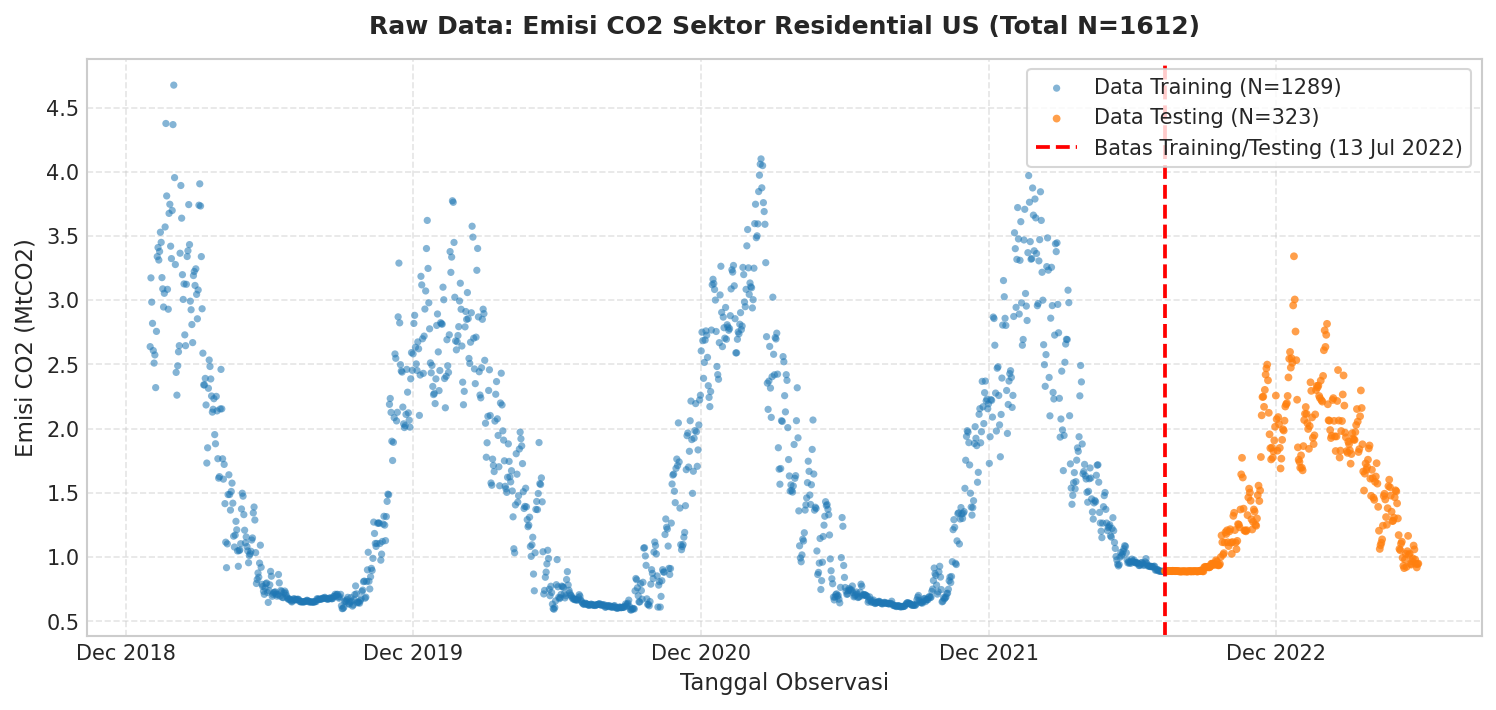

In [3]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 5), dpi=150)

# Titik-titik Data Training dan Testing (Hanya scatter)
ax.scatter(dates_train, y_train, color='#1f77b4', s=12, alpha=0.55, edgecolors='none', label=f'Data Training (N=1289)')
ax.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.75, edgecolors='none', label=f'Data Testing (N=323)')

# Garis batas partisi
ax.axvline(split_date, color='red', linestyle='--', lw=1.8, label=f'Batas Training/Testing (13 Jul 2022)')

ax.set_title(f'Raw Data: Emisi CO2 Sektor Residential US (Total N=1612)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tanggal Observasi', fontsize=11)
ax.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 4. Plot 2: Pemodelan Gaussian Process (GP) Standar Menggunakan GPyTorch

Pemodelan regresi proses Gaussian 1-layer menggunakan GPyTorch dengan kernel RBF tetap (*fixed*):
$$k(x, x') = \sigma_f^2 \exp\left( -\frac{(x - x')^2}{2\ell^2} \right)$$
Parameter: $\ell = 0.20$ tahun, $\sigma_f^2 = 1.0$, dan derau observasi $\sigma_n^2 = 0.05$.

• GPyTorch GP Evaluasi Selesai dalam : 0.8775 detik


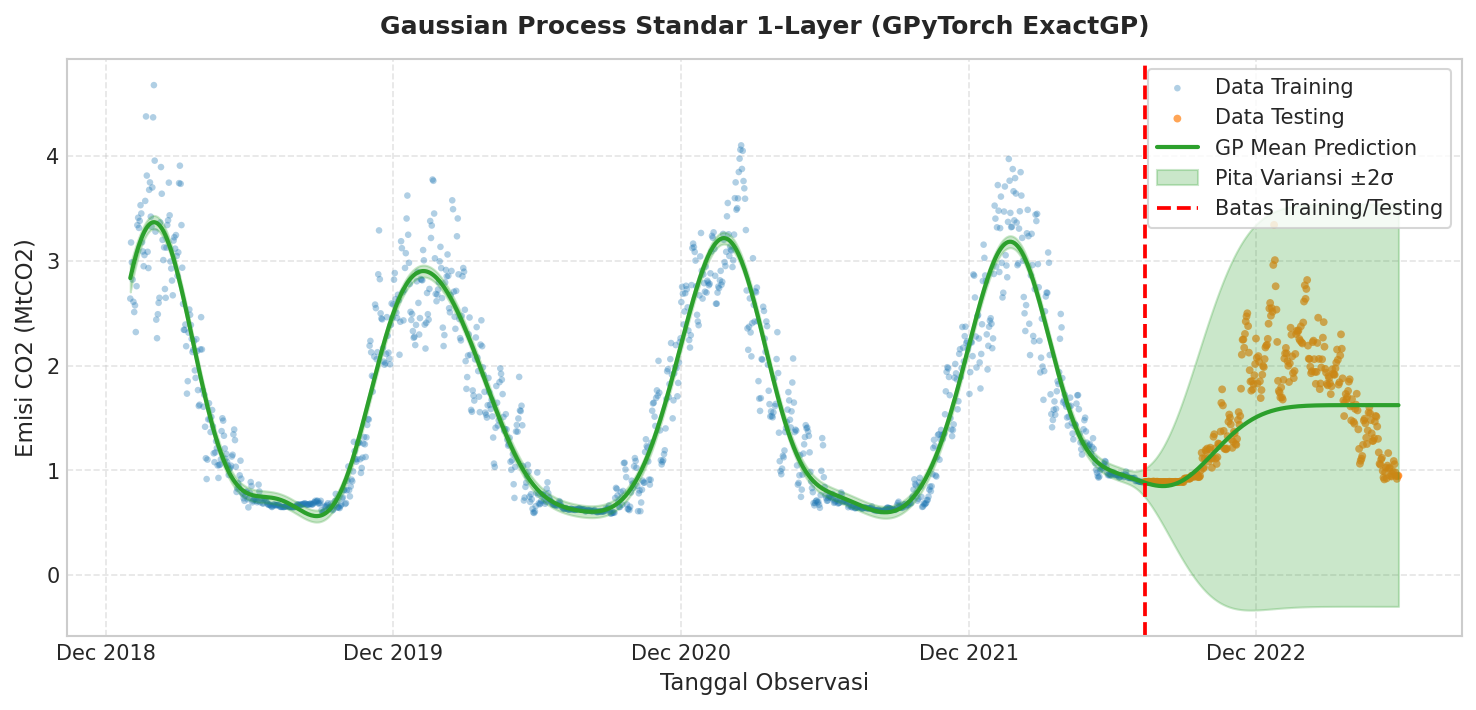

In [4]:
import torch
import gpytorch
import time

# 1. Definisi Model GPyTorch ExactGP
class GPyTorchExactGP(gpytorch.models.ExactGP):
  def __init__(self, train_x, train_y, likelihood, lengthscale=0.20):
    super().__init__(train_x, train_y, likelihood)
    self.mean_module = gpytorch.means.ConstantMean()
    self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.RBFKernel())
    self.mean_module.constant.data.fill_(0.0)
    self.covar_module.outputscale = torch.tensor(1.0)
    self.covar_module.base_kernel.lengthscale = torch.tensor([[lengthscale]])

  def forward(self, x):
    mean_x = self.mean_module(x)
    covar_x = self.covar_module(x)
    return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

# 2. Inisialisasi Model GP Standar
lh_gp = gpytorch.likelihoods.GaussianLikelihood()
lh_gp.noise = torch.tensor(0.05)
model_gp = GPyTorchExactGP(train_x, train_y, lh_gp, lengthscale=0.20)
model_gp.eval()
lh_gp.eval()

t_start = time.time()
with torch.no_grad(), gpytorch.settings.fast_pred_var():
  pred_gp_dense = model_gp(dense_x)
  mu_gp_dense = pred_gp_dense.mean.numpy() * y_std + y_mean
  std_gp_dense = pred_gp_dense.stddev.numpy() * y_std
t_fit_gp = time.time() - t_start

print(f"• GPyTorch GP Evaluasi Selesai dalam : {t_fit_gp:.4f} detik")

# 3. Plotting (Hanya scatter untuk titik data)
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)
ax.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax.plot(dense_dates, mu_gp_dense, color='#2ca02c', lw=2.0, label='GP Mean Prediction')
ax.fill_between(dense_dates, mu_gp_dense - 2*std_gp_dense, mu_gp_dense + 2*std_gp_dense, color='#2ca02c', alpha=0.25, label='Pita Variansi ±2σ')
ax.axvline(split_date, color='red', linestyle='--', lw=1.8, label='Batas Training/Testing')

ax.set_title('Gaussian Process Standar 1-Layer (GPyTorch ExactGP)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tanggal Observasi', fontsize=11)
ax.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 5. Plot 3: Pemodelan Deep Gaussian Process (DGP) 2-Layer Menggunakan GPyTorch 

Komposisi dua proses Gaussian bertingkat:
$$x \xrightarrow{k^{(1)}} h^{(1)} \xrightarrow{k^{(2)}} y$$
Layer 1 memetakan waktu input $x$ ke fitur laten $h^{(1)}$ ($\ell_1 = 0{,}3$, $\sigma_{n1}^2 = 0{,}01$), dan Layer 2 memetakan representasi laten menuju observasi target $y$ ($\ell_2 = 0{,}3$, $\sigma_{n2}^2 = 0{,}03$).

• GPyTorch DGP 2-Layer Evaluasi Selesai dalam : 2.5637 detik


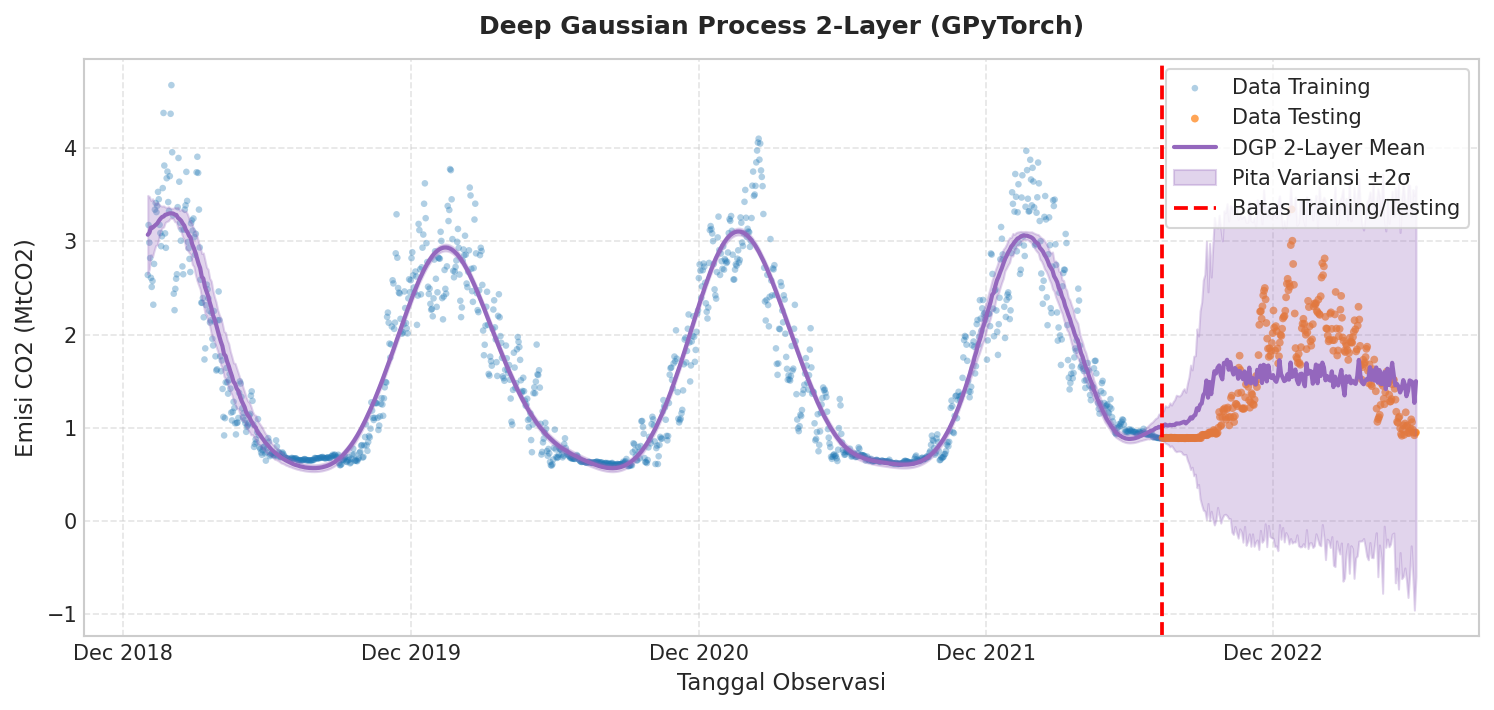

In [5]:
# 1. Setup DGP 2-Layer dengan GPyTorch
h1_train = (train_x - train_x.mean()) / train_x.std()

lh1 = gpytorch.likelihoods.GaussianLikelihood()
lh1.noise = torch.tensor(0.01)
gp1 = GPyTorchExactGP(train_x, h1_train, lh1, lengthscale=0.30)

lh2 = gpytorch.likelihoods.GaussianLikelihood()
lh2.noise = torch.tensor(0.03)
gp2 = GPyTorchExactGP(h1_train, train_y, lh2, lengthscale=0.30)

gp1.eval()
lh1.eval()
gp2.eval()
lh2.eval()

# 2. Forward Propagation 2-Layer
t_start = time.time()
torch.manual_seed(42)
S = 100
with torch.no_grad(), gpytorch.settings.fast_pred_var():
  pred_h1 = gp1(dense_x)
  mu_h1 = pred_h1.mean
  std_h1 = pred_h1.stddev
  eps = torch.randn(S, len(dense_x))
  h1_samples = mu_h1 + std_h1 * eps

  mu_y_s = np.zeros((S, len(dense_x)))
  var_y_s = np.zeros((S, len(dense_x)))
  for s in range(S):
    pred_s = gp2(h1_samples[s])
    mu_y_s[s] = pred_s.mean.numpy()
    var_y_s[s] = pred_s.variance.numpy()

  mu_dgp2_dense = np.mean(mu_y_s, axis=0) * y_std + y_mean
  var_dgp2_norm = np.mean(var_y_s, axis=0) + np.var(mu_y_s, axis=0)
  std_dgp2_dense = np.sqrt(var_dgp2_norm) * y_std
t_fit_dgp2 = time.time() - t_start

print(f"• GPyTorch DGP 2-Layer Evaluasi Selesai dalam : {t_fit_dgp2:.4f} detik")

# 3. Plotting (Hanya scatter untuk titik data)
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)
ax.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax.plot(dense_dates, mu_dgp2_dense, color='#9467bd', lw=2.0, label='DGP 2-Layer Mean')
ax.fill_between(dense_dates, mu_dgp2_dense - 2*std_dgp2_dense, mu_dgp2_dense + 2*std_dgp2_dense, color='#9467bd', alpha=0.28, label='Pita Variansi ±2σ')
ax.axvline(split_date, color='red', linestyle='--', lw=1.8, label='Batas Training/Testing')

ax.set_title('Deep Gaussian Process 2-Layer (GPyTorch)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tanggal Observasi', fontsize=11)
ax.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Plot 4: Pemodelan Deep Gaussian Process (DGP) 3-Layer Menggunakan GPyTorch 

Komposisi tiga proses Gaussian bertingkat:
$$x \xrightarrow{k^{(1)}} h^{(1)} \xrightarrow{k^{(2)}} h^{(2)} \xrightarrow{k^{(3)}} y$$
Model mengomposisikan dua hidden layer laten (masing-masing dengan $\ell = 0{,}3$, $\sigma_n^2 = 0{,}01$) menuju layer output ($\ell_3 = 0{,}3$, $\sigma_{n3}^2 = 0{,}03$).

• GPyTorch DGP 3-Layer Evaluasi Selesai dalam : 4.1413 detik


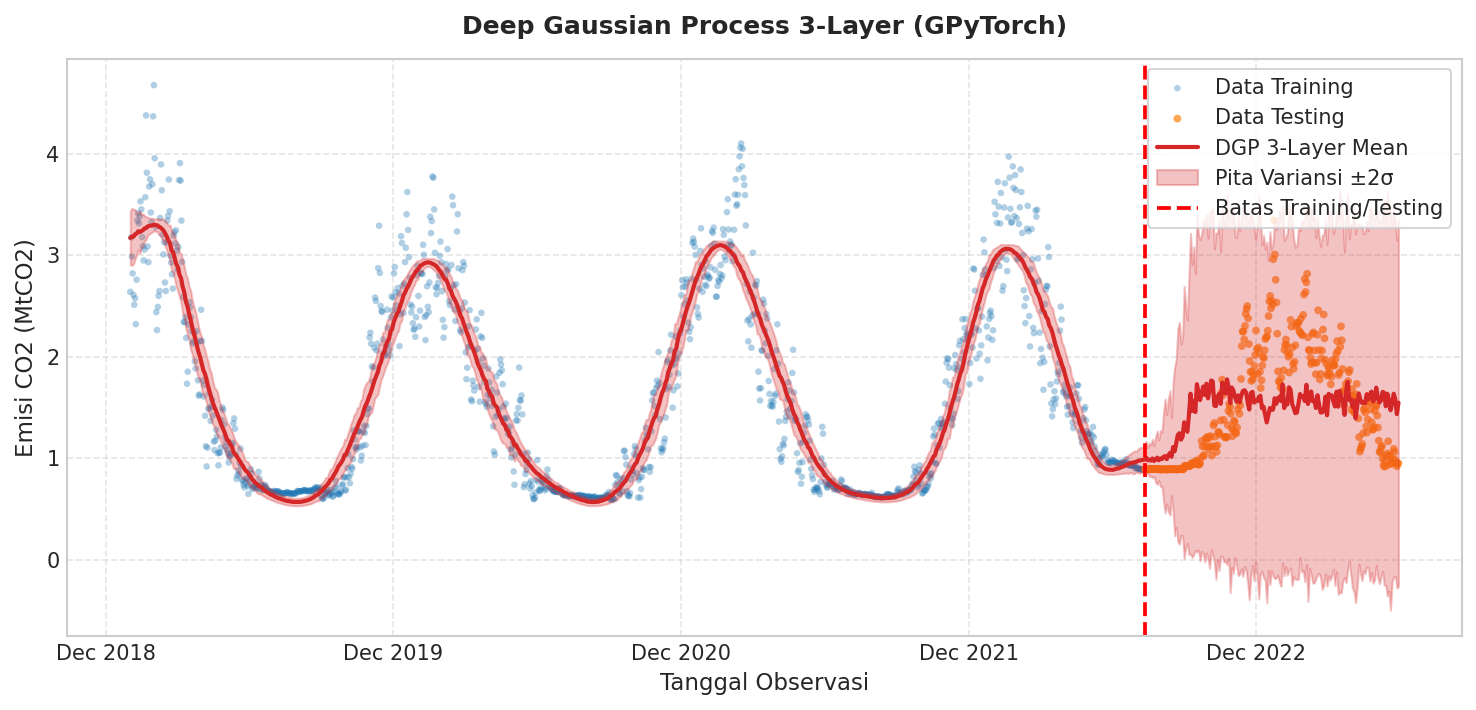

In [6]:
# 1. Setup DGP 3-Layer dengan GPyTorch
h1_3_train = (train_x - train_x.mean()) / train_x.std()
h2_3_train = (train_x - train_x.mean()) / train_x.std()

lh3_1 = gpytorch.likelihoods.GaussianLikelihood()
lh3_1.noise = torch.tensor(0.01)
gp3_1 = GPyTorchExactGP(train_x, h1_3_train, lh3_1, lengthscale=0.30)

lh3_2 = gpytorch.likelihoods.GaussianLikelihood()
lh3_2.noise = torch.tensor(0.01)
gp3_2 = GPyTorchExactGP(h1_3_train, h2_3_train, lh3_2, lengthscale=0.30)

lh3_3 = gpytorch.likelihoods.GaussianLikelihood()
lh3_3.noise = torch.tensor(0.03)
gp3_3 = GPyTorchExactGP(h2_3_train, train_y, lh3_3, lengthscale=0.30)

gp3_1.eval()
lh3_1.eval()
gp3_2.eval()
lh3_2.eval()
gp3_3.eval()
lh3_3.eval()

# 2. Forward Propagation 3-Layer
t_start = time.time()
with torch.no_grad(), gpytorch.settings.fast_pred_var():
  pred_h1_3 = gp3_1(dense_x)
  h1_samples_d3 = pred_h1_3.mean + pred_h1_3.stddev * torch.randn(S, len(dense_x))

  h2_samples_d3 = torch.zeros(S, len(dense_x))
  for s in range(S):
    pred_h2_s = gp3_2(h1_samples_d3[s])
    h2_samples_d3[s] = pred_h2_s.mean + pred_h2_s.stddev * torch.randn(len(dense_x))

  mu_y_s3 = np.zeros((S, len(dense_x)))
  var_y_s3 = np.zeros((S, len(dense_x)))
  for s in range(S):
    pred_s3 = gp3_3(h2_samples_d3[s])
    mu_y_s3[s] = pred_s3.mean.numpy()
    var_y_s3[s] = pred_s3.variance.numpy()

  mu_dgp3_dense = np.mean(mu_y_s3, axis=0) * y_std + y_mean
  var_dgp3_norm = np.mean(var_y_s3, axis=0) + np.var(mu_y_s3, axis=0)
  std_dgp3_dense = np.sqrt(var_dgp3_norm) * y_std
t_fit_dgp3 = time.time() - t_start

print(f"• GPyTorch DGP 3-Layer Evaluasi Selesai dalam : {t_fit_dgp3:.4f} detik")

# 3. Plotting (Hanya scatter untuk titik data)
fig, ax = plt.subplots(figsize=(12, 5), dpi=150)
ax.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax.plot(dense_dates, mu_dgp3_dense, color='#d62728', lw=2.0, label='DGP 3-Layer Mean')
ax.fill_between(dense_dates, mu_dgp3_dense - 2*std_dgp3_dense, mu_dgp3_dense + 2*std_dgp3_dense, color='#d62728', alpha=0.28, label='Pita Variansi ±2σ')
ax.axvline(split_date, color='red', linestyle='--', lw=1.8, label='Batas Training/Testing')

ax.set_title('Deep Gaussian Process 3-Layer (GPyTorch)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tanggal Observasi', fontsize=11)
ax.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper right', frameon=True, fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

---
## 7. Komparasi 4 Panel dalam Satu Figur (2x2 Subplots)

Keempat visualisasi disandingkan secara berdampingan dalam satu kanvas figur 2x2 berkualitas tinggi.

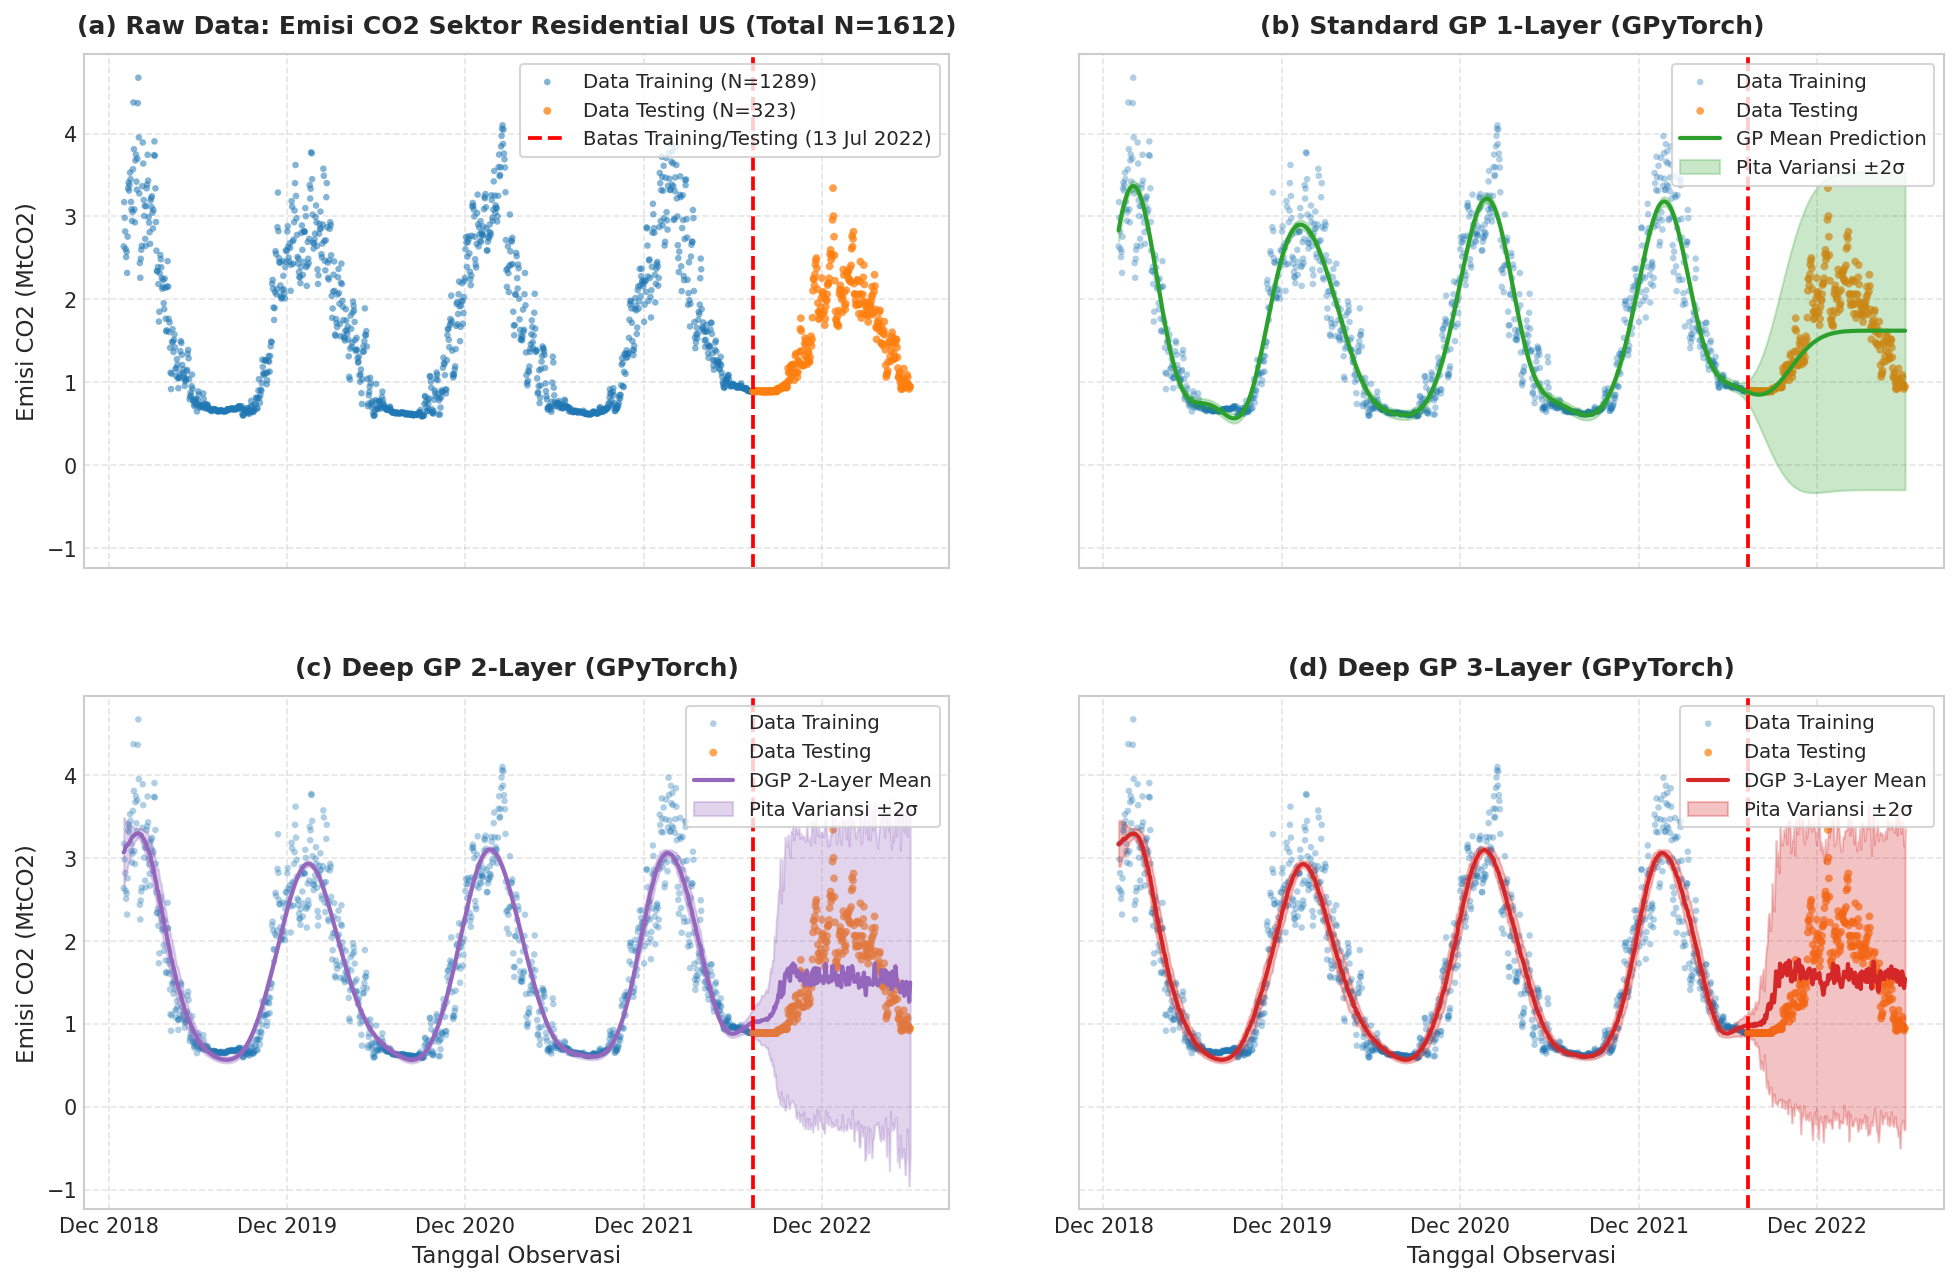

Figur 4-panel berhasil disimpan di: figures/us_residential_gp_dgp_comparison.png dan figures/us_residential_gp_dgp_comparison.pdf


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True, dpi=300)
plt.subplots_adjust(hspace=0.25, wspace=0.15)

# Panel A: Raw Data
ax1 = axes[0, 0]
ax1.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.55, edgecolors='none', label=f'Data Training (N=1289)')
ax1.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.75, edgecolors='none', label=f'Data Testing (N=323)')
ax1.axvline(split_date, color='red', linestyle='--', lw=1.8, label='Batas Training/Testing (13 Jul 2022)')
ax1.set_title(f'(a) Raw Data: Emisi CO2 Sektor Residential US (Total N=1612)', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax1.legend(loc='upper right', frameon=True, fontsize=9.5)
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel B: Standard GP
ax2 = axes[0, 1]
ax2.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax2.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax2.plot(dense_dates, mu_gp_dense, color='#2ca02c', lw=2.0, label='GP Mean Prediction')
ax2.fill_between(dense_dates, mu_gp_dense - 2*std_gp_dense, mu_gp_dense + 2*std_gp_dense, color='#2ca02c', alpha=0.25, label='Pita Variansi ±2σ')
ax2.axvline(split_date, color='red', linestyle='--', lw=1.8)
ax2.set_title('(b) Standard GP 1-Layer (GPyTorch)', fontsize=12, fontweight='bold', pad=10)
ax2.legend(loc='upper right', frameon=True, fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5)

# Panel C: DGP 2-Layer
ax3 = axes[1, 0]
ax3.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax3.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax3.plot(dense_dates, mu_dgp2_dense, color='#9467bd', lw=2.0, label='DGP 2-Layer Mean')
ax3.fill_between(dense_dates, mu_dgp2_dense - 2*std_dgp2_dense, mu_dgp2_dense + 2*std_dgp2_dense, color='#9467bd', alpha=0.28, label='Pita Variansi ±2σ')
ax3.axvline(split_date, color='red', linestyle='--', lw=1.8)
ax3.set_title('(c) Deep GP 2-Layer (GPyTorch)', fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel('Tanggal Observasi', fontsize=11)
ax3.set_ylabel('Emisi CO2 (MtCO2)', fontsize=11)
ax3.legend(loc='upper right', frameon=True, fontsize=9.5)
ax3.grid(True, linestyle='--', alpha=0.5)

# Panel D: DGP 3-Layer
ax4 = axes[1, 1]
ax4.scatter(dates_train, y_train, color='#1f77b4', s=10, alpha=0.35, edgecolors='none', label='Data Training')
ax4.scatter(dates_test, y_test, color='#ff7f0e', s=14, alpha=0.70, edgecolors='none', label='Data Testing')
ax4.plot(dense_dates, mu_dgp3_dense, color='#d62728', lw=2.0, label='DGP 3-Layer Mean')
ax4.fill_between(dense_dates, mu_dgp3_dense - 2*std_dgp3_dense, mu_dgp3_dense + 2*std_dgp3_dense, color='#d62728', alpha=0.28, label='Pita Variansi ±2σ')
ax4.axvline(split_date, color='red', linestyle='--', lw=1.8)
ax4.set_title('(d) Deep GP 3-Layer (GPyTorch)', fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel('Tanggal Observasi', fontsize=11)
ax4.legend(loc='upper right', frameon=True, fontsize=9.5)
ax4.grid(True, linestyle='--', alpha=0.5)

for ax in axes.flat:
  ax.xaxis.set_major_locator(mdates.MonthLocator(interval=12))
  ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

os.makedirs('figures', exist_ok=True)
png_fig_path = 'figures/us_residential_gp_dgp_comparison.png'
pdf_fig_path = 'figures/us_residential_gp_dgp_comparison.pdf'
plt.savefig(png_fig_path, dpi=300, bbox_inches='tight')
plt.savefig(pdf_fig_path, format='pdf', bbox_inches='tight')
plt.show()
print(f"Figur 4-panel berhasil disimpan di: {png_fig_path} dan {pdf_fig_path}")

---
## 8. Kesimpulan Pemodelan

1. **Framework GPyTorch**: Seluruh model diimplementasikan secara terstruktur menggunakan `gpytorch.models.ExactGP`, memanfaatkan operasi tensor PyTorch dan inferensi berbasis aljabar linier teroptimasi.
2. **Karakteristik Ketidakpastian**: Model Deep Gaussian Process bertingkat (2-layer dan 3-layer) menghasilkan prediksi mean musiman yang adaptif serta pita variansi $\pm 2\sigma$ yang mencerminkan perambatan ketidakpastian representasi fitur laten pada data deret waktu.